# Plot gallery

A tour of the plots in `arcsine_laws.plots`, built on the samplers in `arcsine_laws.walks`.

In [137]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

from arcsine_laws import (
    brownian_refinements,
    donsker,
    gaussian,
    rademacher,
    random_walk,
    
)
from arcsine_laws.plots import Colors, plot_histogram, plot_paths, plot_refinements

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## A simple random walk

Flip a fair coin, step up on heads and down on tails.

Text(0.5, 1.0, 'One simple random walk, 50 steps')

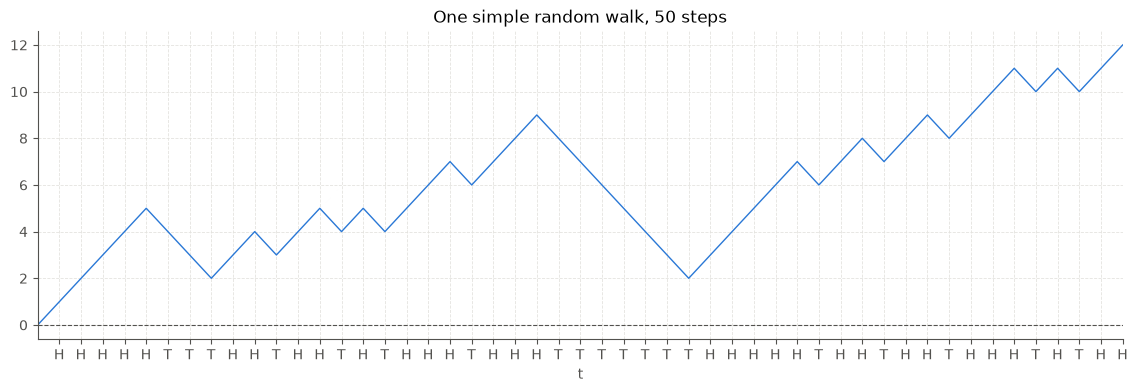

In [142]:
rng = np.random.default_rng(156)
walk = random_walk(50, rademacher(), rng=rng)

HT = {1: 'H', -1: 'T'}
flips = [HT.get(dx) for dx in walk.dx.flatten()]

fig, ax = plt.subplots(figsize=(14, 4))
plot_paths(ax, walk)
ax.set_xticks(np.arange(1, walk.t.max() + 1))
ax.set_xticklabels(flips)
ax.set_title(f"One simple random walk, {walk.n_steps} steps")

Text(0.5, 1.0, 'One simple random walk, 100000 steps')

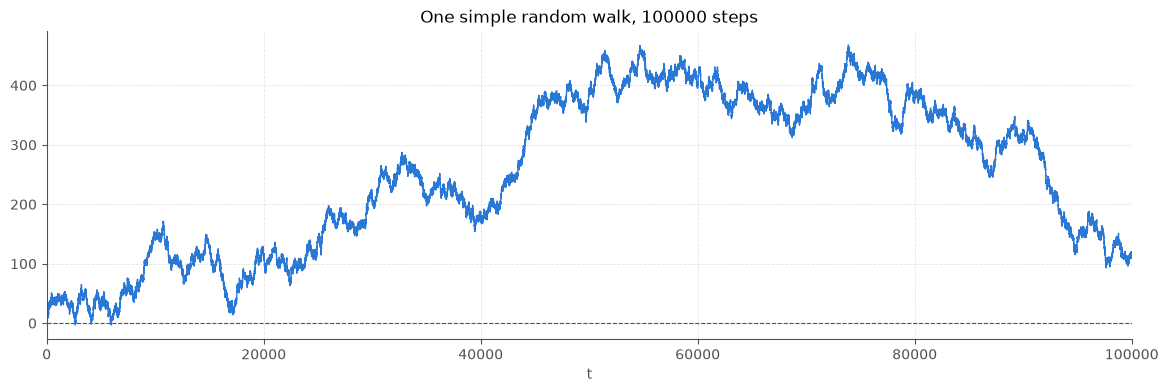

In [143]:
rng = np.random.default_rng(156)
walk = random_walk(100_000, rademacher(), rng=rng)

fig, ax = plt.subplots(figsize=(14, 4))
plot_paths(ax, walk)
ax.set_title(f"One simple random walk, {walk.n_steps} steps")

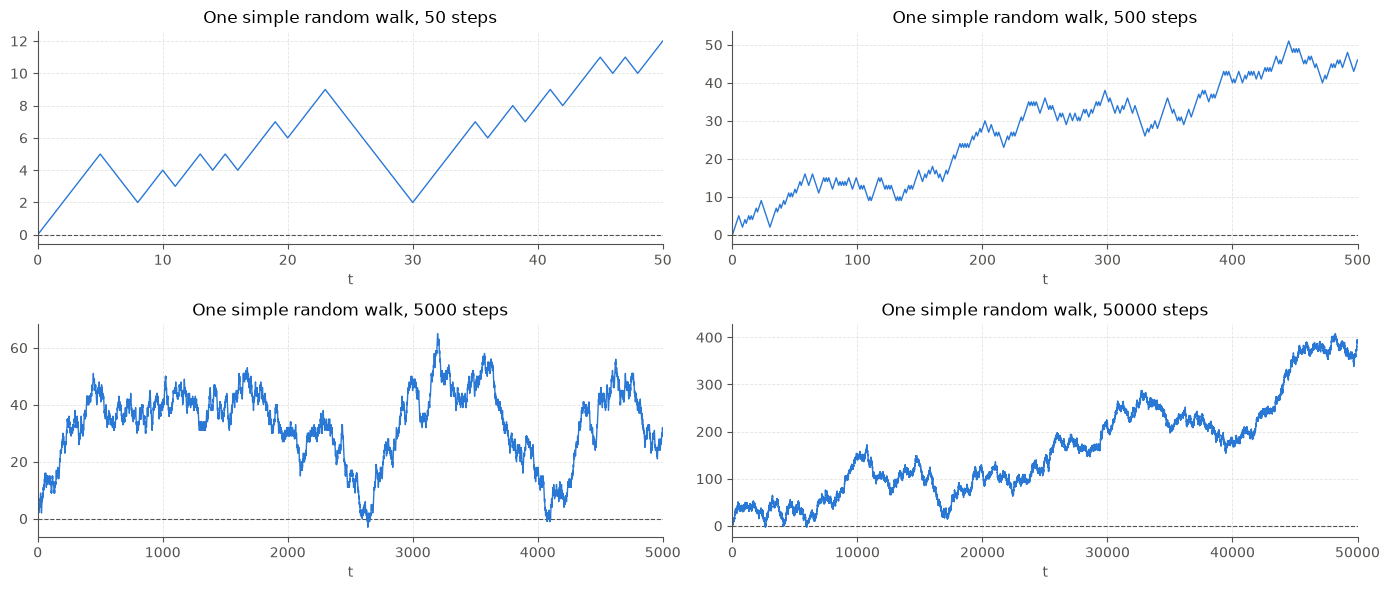

In [145]:
fig, axs = plt.subplots(2, 2, figsize=(14, 6), layout='tight')

for endidx, ax in zip([50, 500, 5_000, 50_000], axs.flatten()):
    plot_paths(ax, walk[:endidx + 1])
    ax.set_title(f"One simple random walk, {walk[:endidx + 1].n_steps} steps")

## Many walks

A fan of 200 walks, with one picked out. Where the fan is darker, more walks pass through.

Text(0.5, 1.0, '500 simple random walks, 100 steps each')

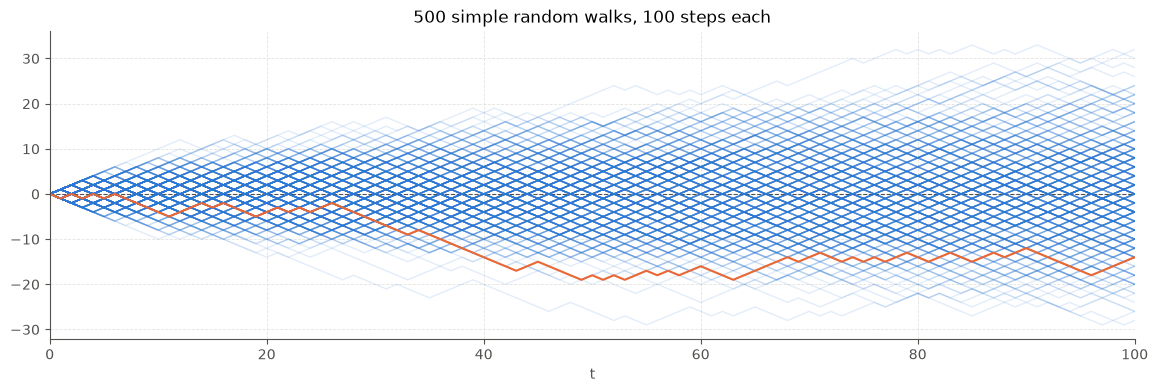

In [75]:
STEPS = 100
N_PATHS = 100 * 5

walks = random_walk(STEPS, rademacher(), n_paths=N_PATHS, rng=rng)

fig, ax = plt.subplots(figsize=(14, 4))
plot_paths(ax, walks, highlight=0)
ax.set_title(f"{walks.n_paths} simple random walks, {walks.n_steps} steps each")

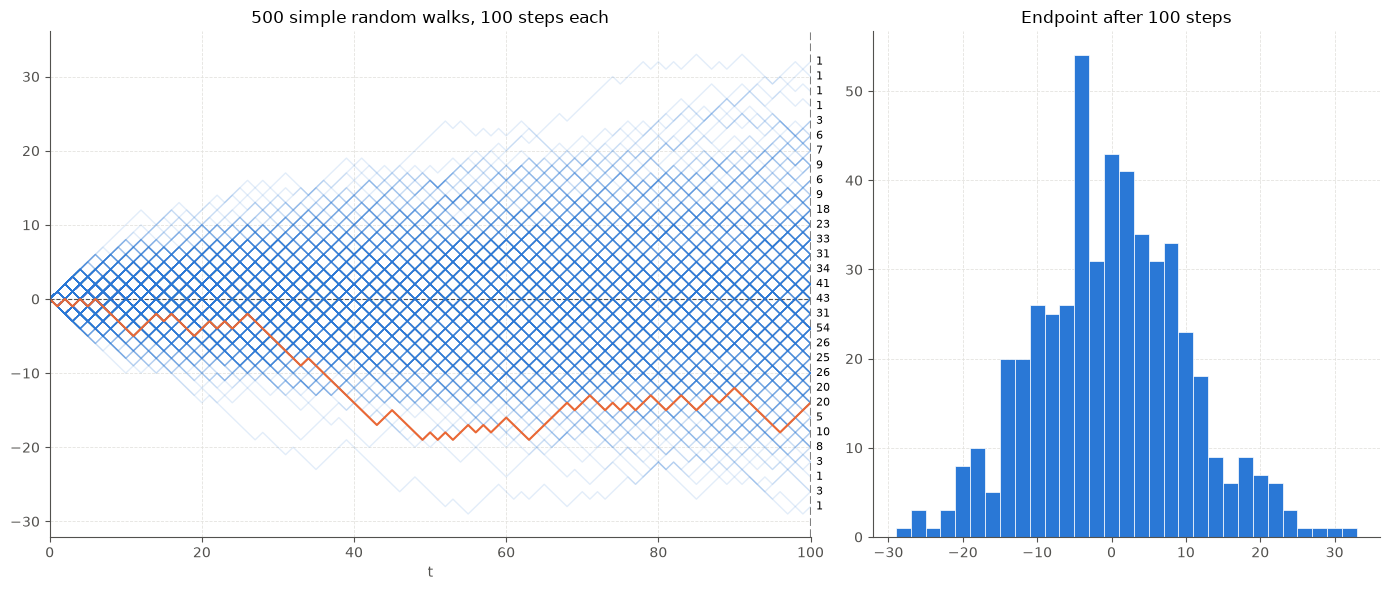

In [84]:
fig, axs = plt.subplots(1, 2, width_ratios=[3, 2], figsize=(14, 6))

plot_paths(axs[0], walks, highlight=0)
axs[0].set_title(f"{walks.n_paths} simple random walks, {walks.n_steps} steps each")

axs[0].axvline(walks.t.max(), linestyle='--', color='grey')

uc = np.unique_counts(walks.x[:, -1])
for c, v in zip(uc.counts, uc.values):
    axs[0].annotate(
        str(c),
        (walks.t[-1], v),
        xytext=(4, 0),
        textcoords="offset points",
        verticalalignment="center",
        fontsize=8,
    )

plot_histogram(axs[1], walks.x[:, -1], density=False)
axs[1].set_title(f"Endpoint after {walks.n_steps} steps")
fig.tight_layout()

In [88]:
STEPS = 100
N_PATHS = 100 * 500

many_walks = random_walk(STEPS, rademacher(), n_paths=N_PATHS, rng=rng)

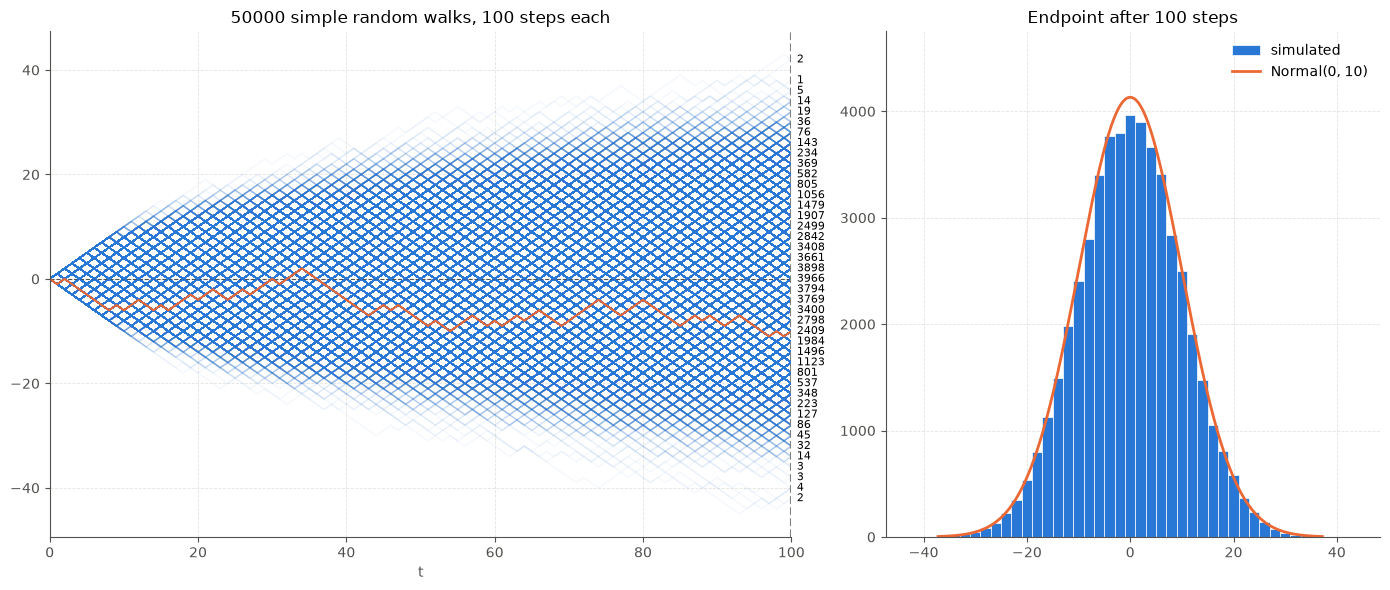

In [89]:
fig, axs = plt.subplots(1, 2, width_ratios=[3, 2], figsize=(14, 6))

plot_paths(axs[0], many_walks, highlight=0)
axs[0].set_title(f"{many_walks.n_paths} simple random walks, {many_walks.n_steps} steps each")

axs[0].axvline(many_walks.t.max(), linestyle='--', color='grey')
uc = np.unique_counts(many_walks.x[:, -1])
for c, v in zip(uc.counts, uc.values):
    axs[0].annotate(
        str(c),
        (many_walks.t[-1], v),
        xytext=(4, 0),
        textcoords="offset points",
        verticalalignment="center",
        fontsize=8,
    )

plot_histogram(
    axs[1], 
    many_walks.x[:, -1], 
    density=False, 
    reference=stats.norm(0, np.sqrt(STEPS)), 
    reference_label=f"Normal(0, 10)"
)
axs[1].set_title(f"Endpoint after {many_walks.n_steps} steps")
fig.tight_layout()

In [110]:
walk.x

array([[0., 1., 2., 3., 2., 1., 0., 1., 2., 1., 2., 3., 4., 5., 4., 3.,
        2., 3., 4., 5., 6., 5., 4., 3., 4., 3., 4., 3., 4., 5., 4., 5.,
        6., 7., 6., 7., 8., 9., 8., 7., 8., 9., 8., 7., 6., 5., 6., 5.,
        4., 5., 6.]])

About  4 paths out of 100 end at 6.
About 20 paths out of 100 end at 6 or larger.


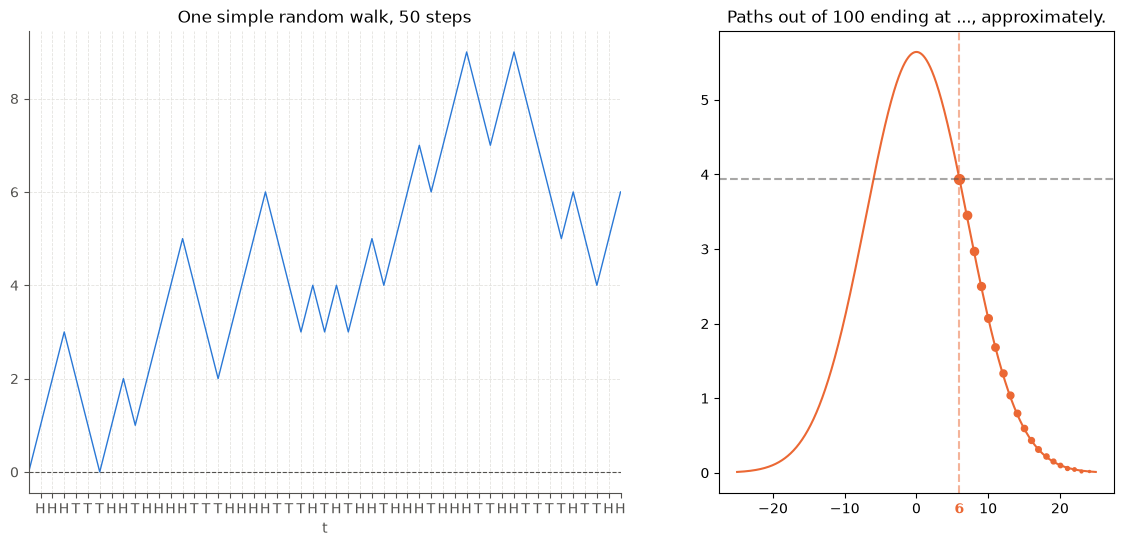

In [136]:
rng = np.random.default_rng(1729)
walk = random_walk(50, rademacher(), rng=rng)

HT = {1: 'H', -1: 'T'}
flips = [HT.get(dx) for dx in walk.dx.flatten()]

fig, axs = plt.subplots(1, 2, width_ratios=[3, 2], figsize=(14, 6))
plot_paths(axs[0], walk)
axs[0].set_xticks(np.arange(1, walk.t.max() + 1))
axs[0].set_xticklabels(flips)
axs[0].set_title(f"One simple random walk, {walk.n_steps} steps")

ts = np.linspace(-25, 25, num=1000)
dnorm = stats.norm(0, np.sqrt(walk.n_steps))
axs[1].plot(ts, 100 * dnorm.pdf(ts), color=Colors.ORANGE)

endpt = walk.x.flatten()[-1]
axs[1].scatter(endpt, 100 * dnorm.pdf(endpt), color=Colors.ORANGE, s=50)
for e in range(int(endpt), 25 + 1):
    axs[1].scatter(e, 100 * dnorm.pdf(e), color=Colors.ORANGE, s=50 - 2*e)
axs[1].axvline(endpt, color=Colors.ORANGE, linestyle='--', alpha=0.5)
# Label where the vline meets the x-axis, styled like an orange tick label.
# x is in data coordinates, y in axes coordinates (0 is the bottom spine).
axs[1].annotate(
    f"{endpt:g}",
    xy=(endpt, 0),
    xycoords=axs[1].get_xaxis_transform(),
    # Same offset and size as the tick labels: tick length plus padding.
    xytext=(0, -(plt.rcParams["xtick.major.size"] + plt.rcParams["xtick.major.pad"])),
    textcoords="offset points",
    horizontalalignment="center",
    verticalalignment="top",
    fontsize=plt.rcParams["xtick.labelsize"],
    color=Colors.ORANGE,
    fontweight="bold",
)
axs[1].axhline(100 * dnorm.pdf(endpt), color=Colors.INK, linestyle='--', alpha=0.5)

axs[1].set_title(f"Paths out of 100 ending at ..., approximately.")


print(f"About {100 * dnorm.pdf(endpt):2.0f} paths out of 100 end at 6.")
print(f"About {100 * (1 - dnorm.cdf(endpt)):2.0f} paths out of 100 end at 6 or larger.")

## Zooming out: Donsker scaling

Squash n steps into the interval [0, 1] and shrink space by sqrt(n). As n grows the walk looks more and more like Brownian motion.

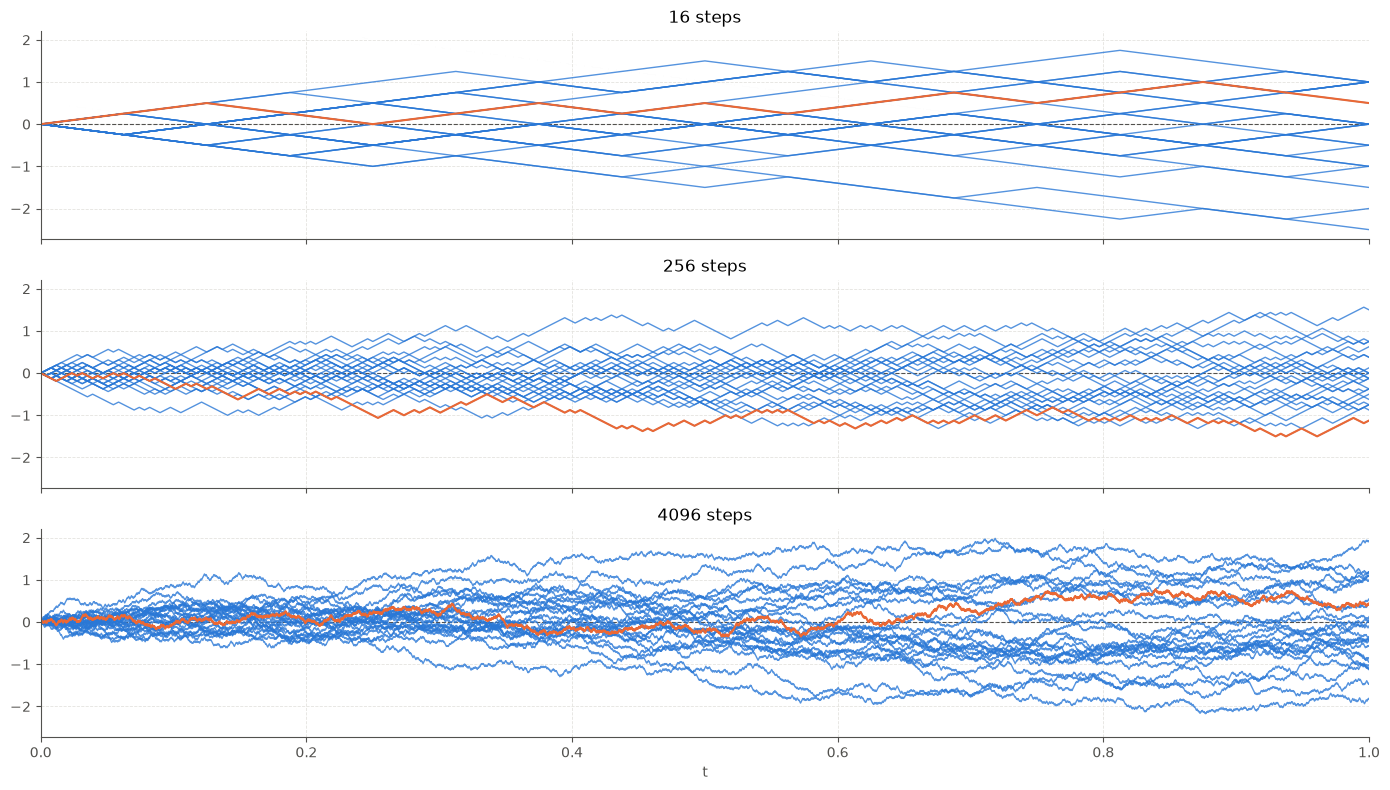

In [37]:
fig, axs = plt.subplots(3, 1, figsize=(14, 8), sharex=True, sharey=True)
for ax, n_steps in zip(axs, [16, 256, 4096]):
    walk = random_walk(n_steps, rademacher(), n_paths=25, rng=rng)
    plot_paths(ax, donsker(walk), alpha=0.8, highlight=0)
    ax.set_title(f"{n_steps} steps")
axs[0].set_xlabel("")
axs[1].set_xlabel("")
fig.tight_layout()

## Brownian motion, exactly on a grid

With Gaussian steps of variance dt, a random walk *is* Brownian motion observed every dt.

Text(0.5, 1.0, '200 Brownian motion paths on [0, 1]')

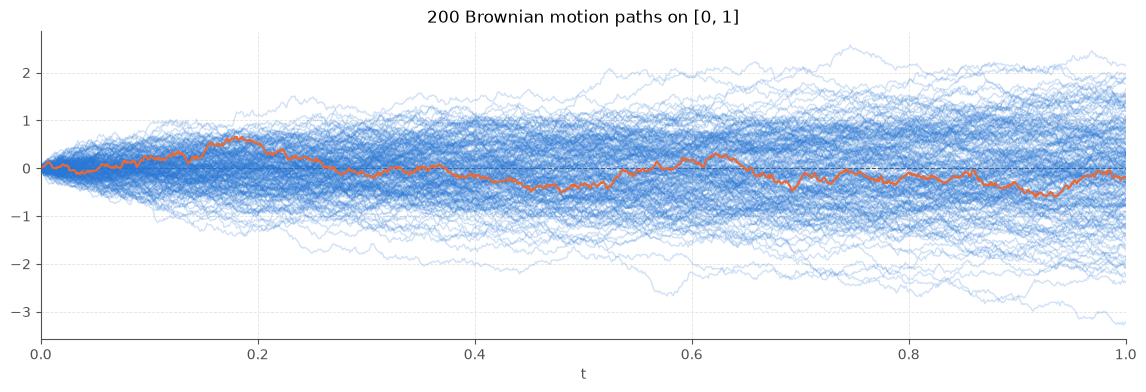

In [18]:
n_steps = 1024
bm = random_walk(n_steps, gaussian(variance=1/n_steps), n_paths=200, dt=1/n_steps, rng=rng)

fig, ax = plt.subplots(figsize=(14, 4))
plot_paths(ax, bm, highlight=0)
ax.set_title("200 Brownian motion paths on [0, 1]")

## Brownian motion by midpoint refinement

Start from B(0) = 0 and a random B(1). Repeatedly fill in each midpoint from the Brownian bridge between its neighbours. Each level keeps every point of the one before.

Text(0.5, 1.0, 'The first five midpoint refinements')

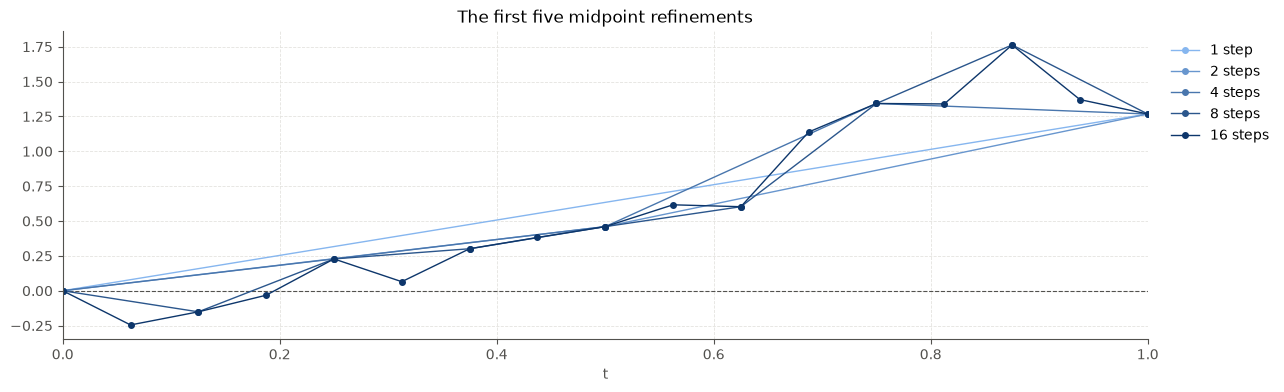

In [19]:
refinements = brownian_refinements(20, rng=rng)

fig, ax = plt.subplots(figsize=(14, 4))
plot_refinements(ax, refinements[:5])
ax.set_title("The first five midpoint refinements")

Text(0.5, 1.0, 'Every other level, down to 1024 steps')

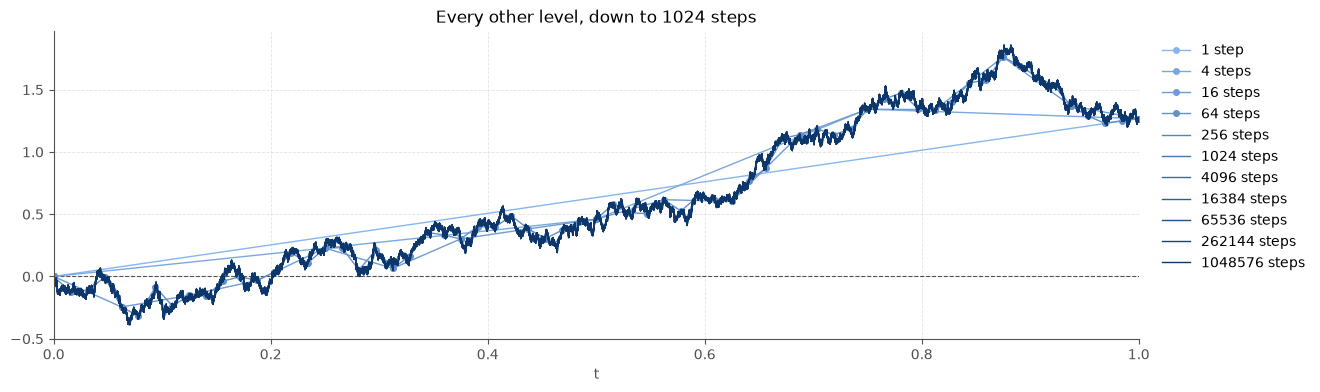

In [20]:
fig, ax = plt.subplots(figsize=(14, 4))
plot_refinements(ax, refinements[::2])
ax.set_title("Every other level, down to 1024 steps")

## The central limit theorem

The endpoint of a Donsker scaled walk is approximately N(0, 1). Each bar is one possible endpoint; with few steps there are only a handful.

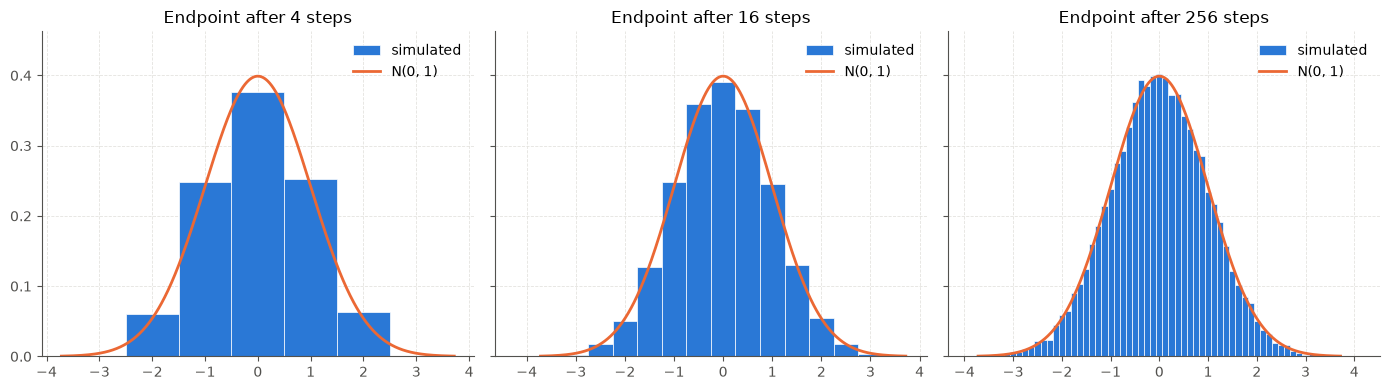

In [21]:
fig, axs = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, n_steps in zip(axs, [4, 16, 256]):
    walks = donsker(random_walk(n_steps, rademacher(), n_paths=20_000, rng=rng))
    plot_histogram(ax, walks.x[:, -1], reference=stats.norm(0, 1), reference_label="N(0, 1)")
    ax.set_title(f"Endpoint after {n_steps} steps")
fig.tight_layout()